In [ ]:
import os
import sys
import warnings

sys.path.append("/path/to/GeneSPOT")
warnings.filterwarnings("ignore")
os.environ['R_HOME'] = '/path/to/R'

In [2]:
from pathlib import Path
from adjustText import adjust_text
import matplotlib
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import mudata as mu
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
from tqdm import tqdm
from scipy.spatial import ConvexHull
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
from statannotations.Annotator import Annotator
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import adjusted_rand_score

matplotlib.rcParams['font.family'] = 'Aptos'
matplotlib.rcParams['pdf.fonttype'] = 42

In [3]:
from palettable.cartocolors.diverging import TealRose_7
from palettable.lightbartlein.diverging import BlueOrange8_8
from palettable.lightbartlein.sequential import Blues7_6
from palettable.cartocolors.diverging import Tropic_7
from palettable.cartocolors.sequential import PurpOr_7, agSunset_7

In [4]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything
from genespot.preprocess import preprocess_adata, filter_features, concat_features
from vendor.niche_embedding.SpatialGlue.utils import clustering
from vendor.niche_embedding.SpatialGlue.SpatialGlue_pyG import Train_SpatialGlue
from vendor.niche_embedding.SpatialGlue.preprocess import pca, clr_normalize_each_cell, construct_neighbor_graph
from genespot.genespot import build_graph, topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import plot_clusters_with_density_and_edges, create_cmap, legend_handles

random_state = 42
seed_everything(random_state)

In [ ]:
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/res/paired')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/outputs/paired')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [6]:
raw_path = '/path/to/data/SMA_aligned/output'
a1_mdata = mu.read_h5mu(os.path.join(raw_path, 'A1.h5mu'))

annotations = ['ACB', 'CP_intact', 'CP_lesioned', 'CTX', 'LSX', 'MSC', 'OT', 'VL', 'aco', 'cc']
annotations_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
a1_mdata.uns['Annotation_colors'] = annotations_colors
annotations_legends = legend_handles(annotations, annotations_colors)
annotation_color_map = dict(
    zip(annotations, annotations_colors)
)

For Genes: 
Before filter:  (2675, 16263)
After filter:  (2675, 11260)
# HVG:  2000
For Metabolisms: 
Before filter:  (2675, 1248)
After filter:  (2675, 1248)
# HVM:  50


R callback write-console:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.
  


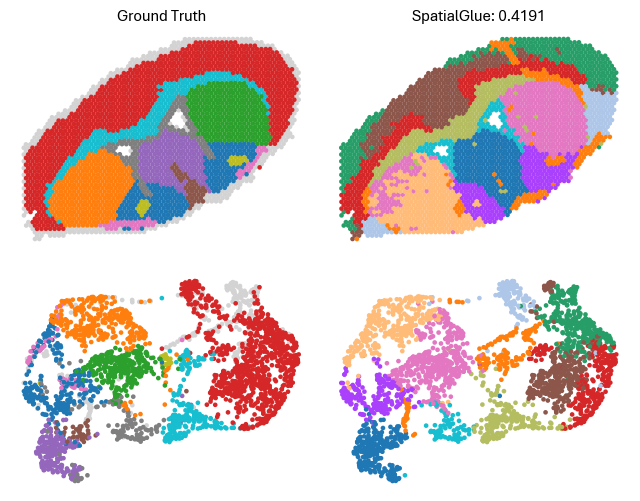

In [7]:
######### Original Performance for A1 #########
mdata = a1_mdata.copy()
######### Highly-Variance Features #########
rna_adata = mdata['rna'].copy()
print('For Genes: ')
print('Before filter: ', rna_adata.shape)
sc.pp.filter_genes(rna_adata, min_cells=50)
print('After filter: ', rna_adata.shape)
rna_adata = preprocess_adata(rna_adata)
hvg_genes = filter_features(rna_adata, layer='raw', n_variable_genes=2000, expr_percent_filter=False)
print('# HVG: ', len(hvg_genes))

mb_adata = mdata['msi'].copy()
print('For Metabolisms: ')
print('Before filter: ', mb_adata.shape)
print('After filter: ', mb_adata.shape)
mb_adata = preprocess_adata(mb_adata)
hvg_mbs = filter_features(mb_adata, layer='raw', n_variable_genes=50, expr_percent_filter=False)
print('# HVM: ', len(hvg_mbs))
hvg_features = hvg_genes.tolist() + hvg_mbs.tolist()

######### SpatailGLUE #########
rna_adata_glue = rna_adata[:, hvg_genes].copy()
rna_adata_glue.obsm['feat'] = pca(rna_adata_glue, n_comps=50, random_state=random_state)
mb_adata_glue = mb_adata[:, hvg_mbs].copy()
mb_adata_glue.obsm['feat'] = pca(mb_adata_glue, n_comps=50, random_state=random_state)

glue_data = construct_neighbor_graph(rna_adata_glue, mb_adata_glue, datatype='10x', n_neighbors=18)
model = Train_SpatialGlue(glue_data, datatype='10x', device='cuda:0', random_seed=random_state)
output = model.train()
mdata.obsm['emb_latent_omics1'] = output['emb_latent_omics1']
mdata.obsm['emb_latent_omics2'] = output['emb_latent_omics2']
mdata.obsm['SpatialGlue'] = output['SpatialGlue']
mdata.obsm['alpha'] = output['alpha']
mdata.obsm['alpha_omics1'] = output['alpha_omics1']
mdata.obsm['alpha_omics2'] = output['alpha_omics2']

######### Clustering #########
clustering(mdata, key='SpatialGlue', add_key='SpatialGlue', n_clusters=mdata.obs['Annotation'].unique().shape[0], method='mclust', use_pca=True)

obs_df = mdata.obs.dropna()
ARI = adjusted_rand_score(obs_df['Annotation'], obs_df['SpatialGlue'])

fig, axs = plt.subplots(2, 2, figsize=(8, 6))
sc.pl.embedding(mdata, color='Annotation', basis='spatial', title='Ground Truth', ax=axs[0][0], show=False, legend_loc=None, frameon=False)
sc.pl.embedding(mdata, color='SpatialGlue', basis='spatial', title=f'SpatialGlue: {ARI:.4f}', ax=axs[0][1], show=False, legend_loc=None, frameon=False)
sc.pp.neighbors(mdata, use_rep='SpatialGlue', random_state=random_state)
sc.tl.umap(mdata, random_state=random_state)
sc.pl.umap(mdata, color='Annotation', title='', show=False, ax=axs[1][0], legend_loc=None, frameon=False)
sc.pl.umap(mdata, color='SpatialGlue', title='', show=False, ax=axs[1][1], legend_loc=None, frameon=False)

plt.subplots_adjust(wspace=0.05, hspace=0.1)
plt.show()

In [8]:
filtered_mdata = mdata[mdata.obs['Annotation'].notna()]
rna_adata = filtered_mdata['rna'].copy()
mb_adata = filtered_mdata['msi'].copy()
sc.pp.normalize_total(rna_adata, target_sum=1e4)
sc.pp.normalize_total(mb_adata, target_sum=1e4)

In [9]:
hvg_genes = filter_features(rna_adata, layer='raw', n_variable_genes=2000, expr_percent_filter=True, min_expr_percent=0.1, max_expr_percent=1)
hvg_mbs = filter_features(mb_adata, layer='raw', n_variable_genes=200, expr_percent_filter=True, min_expr_percent=0.1, max_expr_percent=1)
hvg_features = hvg_genes.tolist() + hvg_mbs.tolist()
print(f'#Genes: {len(hvg_genes)}, #MBs: {len(hvg_mbs)}')

paired_adata = concat_features(
    [rna_adata, mb_adata],
    feature_groups=['Gene', 'Metabolite']
)
paired_adata.obs['SpatialGlue'] = filtered_mdata.obs['SpatialGlue']
paired_adata.obsm['SpatialGlue'] = filtered_mdata.obsm['SpatialGlue']
paired_adata.var['feature_names'] = paired_adata.var_names

#Genes: 835, #MBs: 182


In [10]:
cost, running_adata = build_graph(
    paired_adata[paired_adata.obs['Annotation'].notna()][:, hvg_features],
    coarsen=True, coarsen_key='Annotation',
    
    feature_expression_layer='raw', 
    feature_aggregate_func='mean',
    
    add_landmarks=True,
    landmark_key="Annotation",
    landmark_subset=False,
    landmark_expression_value=1.,
    non_landmark_expression_value=0.,
    landmark_prefix='SpatialLandmark',
    
    n_neighbors=20,
    use_rep='SpatialGlue',
    coarsen_method='paga_guided_umap',
    random_state=random_state
)
gstd = cal_ot_distance(running_adata.X, cost, processes=None)

100%|██████████| 526851/526851 [01:11<00:00, 7409.96it/s]


Training: 100%|██████████| 200/200 [01:28<00:00,  2.25it/s, loss=8.07]


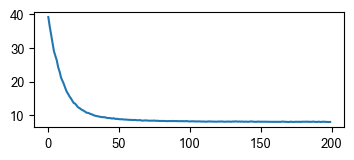

In [11]:
feature_embedding, _, loss = node2vec(
    gstd, 
    dimensions=30,
    n_neighbors=15,
    walk_length=10,
    context_size=10,
    num_walks=200,
    num_negative_samples=1,
    p=1, q=0.5,
    
    workers=5,
    batch_size=128,
    epochs=200,
    lr=1e-2,
    device='cuda:0',
    norm=True
)
fig, ax = plt.subplots(1, 1, figsize=(4, 1.5))
ax.plot(range(len(loss)), loss)
plt.show()

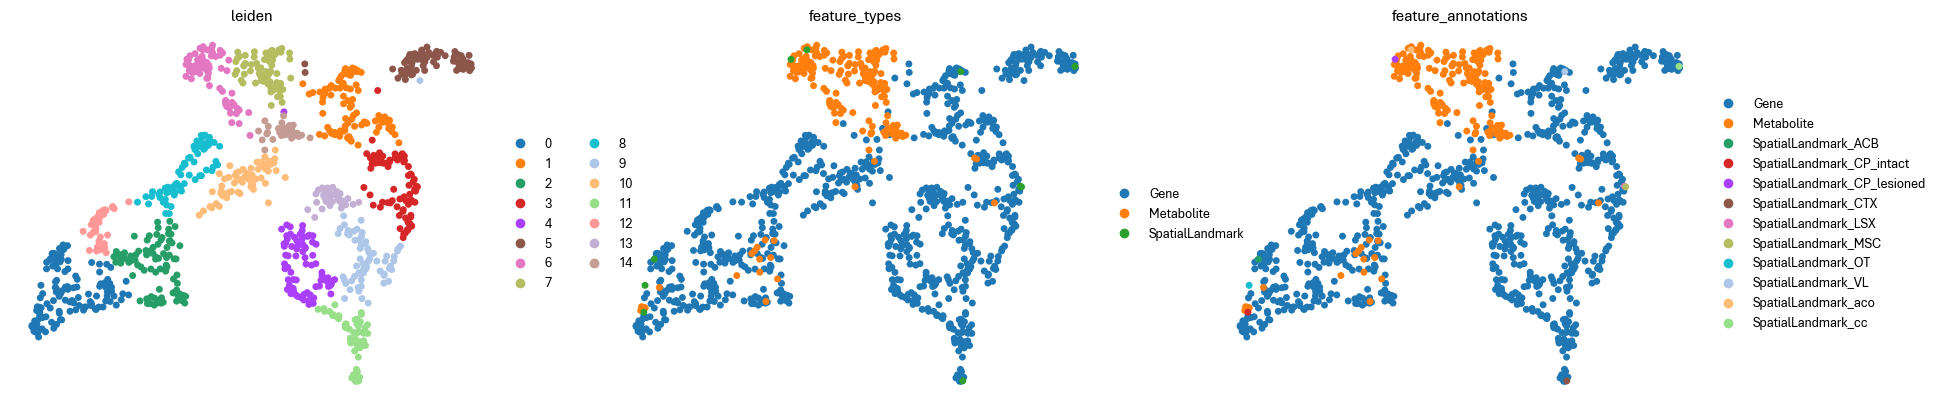

In [12]:
gdata = sc.AnnData(running_adata.X.T)
gdata.obsm['feature_embedding'] = feature_embedding
gdata.obs_names = running_adata.var['feature_names']
gdata.obs['feature_names'] = running_adata.var['feature_names']
gdata.obs['feature_types'] = running_adata.var['feature_types']
gdata.obs['feature_annotations'] = running_adata.var['feature_annotations']
sc.pp.neighbors(gdata, random_state=random_state, use_rep='feature_embedding')
sc.tl.umap(gdata, random_state=random_state)
sc.tl.leiden(gdata, resolution=0.5, random_state=random_state)
sc.pl.umap(gdata, color=['leiden', 'feature_types', 'feature_annotations'], edges=False, frameon=False, alpha=1, size=100)